# TB India v5 -- Appendix Figures & Tables (v59)

This notebook generates **supplementary figures, the appendix parameter tables, and the consolidated outcomes table** for the manuscript.

Main paper figures are in `02_India_TB_v5_figures_main.ipynb`.


In [1]:
import sys, os, json, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

# Local project modules
import params

%matplotlib inline
plt.rcParams['figure.dpi'] = 100
plt.rcParams['savefig.dpi'] = 150

print('Imports complete.')


Imports complete.


In [2]:
# ── Load simulation outputs ──────────────────────────────────────────
base = Path('.')
exp_dirs = sorted(
    [d for d in base.iterdir()
     if d.is_dir() and len(d.name) == 36 and '-' in d.name],
    key=lambda d: d.stat().st_mtime, reverse=True
)

# Load PropertyReport
pr_data = None
for ed in exp_dirs:
    sims = [s for s in ed.iterdir() if s.is_dir()]
    for sim in sims:
        pr_path = sim / 'PropertyReport.json'
        if pr_path.exists():
            with open(pr_path) as f:
                pr_data = json.load(f)
            print(f'Loaded PropertyReport from {ed.name}')
            break
    if pr_data:
        break
if pr_data is None:
    print('WARNING: No PropertyReport.json found.')

# Load ReportEventRecorder
all_events = []
exp_dir_used = None
for ed in exp_dirs:
    sims = [s for s in ed.iterdir() if s.is_dir() and (s / 'ReportEventRecorder.csv').exists()]
    if len(sims) >= 1:
        exp_dir_used = ed
        for i, sim in enumerate(sims):
            df = pd.read_csv(sim / 'ReportEventRecorder.csv')
            df['replicate'] = i
            all_events.append(df)
        break
if all_events:
    event_df = pd.concat(all_events, ignore_index=True)
    print(f'Loaded {len(event_df):,} events from {len(all_events)} replicates')
else:
    event_df = None
    print('WARNING: No ReportEventRecorder.csv found.')

# Analysis window
sim_duration = params.burn_initial + params.burn_predots + 38.0 * 365
analysis_start = sim_duration - 10 * 365
print(f'Analysis window: day {analysis_start:.0f} to {sim_duration:.0f}')
if event_df is not None:
    event_recent = event_df[event_df['Time'] >= analysis_start].copy()
    print(f'Events in analysis window: {len(event_recent):,}')
else:
    event_recent = None


Loaded 4,775,110 events from 50 replicates
Analysis window: day 63875 to 67525
Events in analysis window: 2,151,804


In [3]:
import glob
from pathlib import Path

SCALE = 1e5
model_ts = None
has_mortality = False
base_year = 1970

def sum_pr_channels(pr_channels, base_name, n_steps):
    total = np.zeros(n_steps)
    for ch, val in pr_channels.items():
        if ch.startswith(base_name + ':'):
            total += np.array(val['Data'])
    return total

# Find experiment directory automatically
base = Path('.')
exp_dirs = sorted(
    [d for d in base.iterdir()
     if d.is_dir() and len(d.name) == 36 and '-' in d.name],
    key=lambda d: d.stat().st_mtime, reverse=True
)

experiment_uid = None
for ed in exp_dirs:
    pr_check = list(ed.glob('**/PropertyReportTB.json'))
    if not pr_check:
        pr_check = list(ed.glob('**/PropertyReport.json'))
    if pr_check:
        experiment_uid = str(ed)
        break

if experiment_uid:
    pr_files = sorted(glob.glob(f'{experiment_uid}/**/PropertyReport*.json', recursive=True))
    print(f'Found {len(pr_files)} PropertyReport files in {experiment_uid}')
else:
    pr_files = []
    print('No experiment directory with PropertyReport found.')

if pr_files:
    all_sim_ts = []
    for si, pf in enumerate(pr_files):
        with open(pf) as fp:
            pr = json.load(fp)
        tstep = pr['Header']['Simulation_Timestep']
        n_steps = pr['Header']['Timesteps']
        years_pr = base_year + np.arange(n_steps) * tstep / 365.0

        pop = sum_pr_channels(pr['Channels'], 'Statistical Population', n_steps)
        active = sum_pr_channels(pr['Channels'], 'Active TB Infections', n_steps)
        new_active = sum_pr_channels(pr['Channels'], 'New Active Infections', n_steps)
        new_inf = sum_pr_channels(pr['Channels'], 'New Infections', n_steps)
        dd_cum = sum_pr_channels(pr['Channels'], 'Disease Deaths', n_steps)
        dd_per_ts = np.diff(dd_cum, prepend=0)

        safe_pop = np.maximum(pop, 1)
        prev_pc = active / safe_pop
        inc_active_pc = new_active / safe_pop
        inc_inf_pc = new_inf / safe_pop
        mort_pc = dd_per_ts / safe_pop

        df_ts = pd.DataFrame({
            'Year': years_pr, 'YearInt': years_pr.astype(int),
            'prev_pc': prev_pc, 'inc_active_pc': inc_active_pc,
            'inc_inf_pc': inc_inf_pc, 'mort_pc': mort_pc,
            'pop': pop, 'sim_idx': si
        })

        annual = df_ts.groupby('YearInt').agg(
            prev_pc=('prev_pc', 'mean'),
            inc_active_pc=('inc_active_pc', 'sum'),
            inc_inf_pc=('inc_inf_pc', 'sum'),
            mort_pc=('mort_pc', 'sum'),
            pop=('pop', 'mean'),
        )
        annual['sim_idx'] = si
        all_sim_ts.append(annual)

    model_ts = pd.concat(all_sim_ts)
    model_ts.index.name = 'Year'

    for col in ['prev_pc', 'inc_active_pc', 'inc_inf_pc', 'mort_pc']:
        model_ts[col] *= SCALE

    has_mortality = model_ts['mort_pc'].sum() > 0

    # Aggregate across simulations: mean + 95% CI
    grouped = model_ts.groupby(model_ts.index)
    model_ts_agg = pd.DataFrame(index=grouped.first().index)
    for base, col in [('inc', 'inc_active_pc'), ('prev', 'prev_pc'), ('mort', 'mort_pc')]:
        model_ts_agg[f'{base}_mean'] = grouped[col].mean()
        model_ts_agg[f'{base}_lo'] = grouped[col].quantile(0.025)
        model_ts_agg[f'{base}_hi'] = grouped[col].quantile(0.975)
    model_ts = model_ts_agg

    print(f'Aggregated: {list(model_ts.columns)}')
else:
    print('Skipping time series.')



Found 50 PropertyReport files in 0f9759ae-144f-f111-92e4-000d3af5294c
Aggregated: ['inc_mean', 'inc_lo', 'inc_hi', 'prev_mean', 'prev_lo', 'prev_hi', 'mort_mean', 'mort_lo', 'mort_hi']


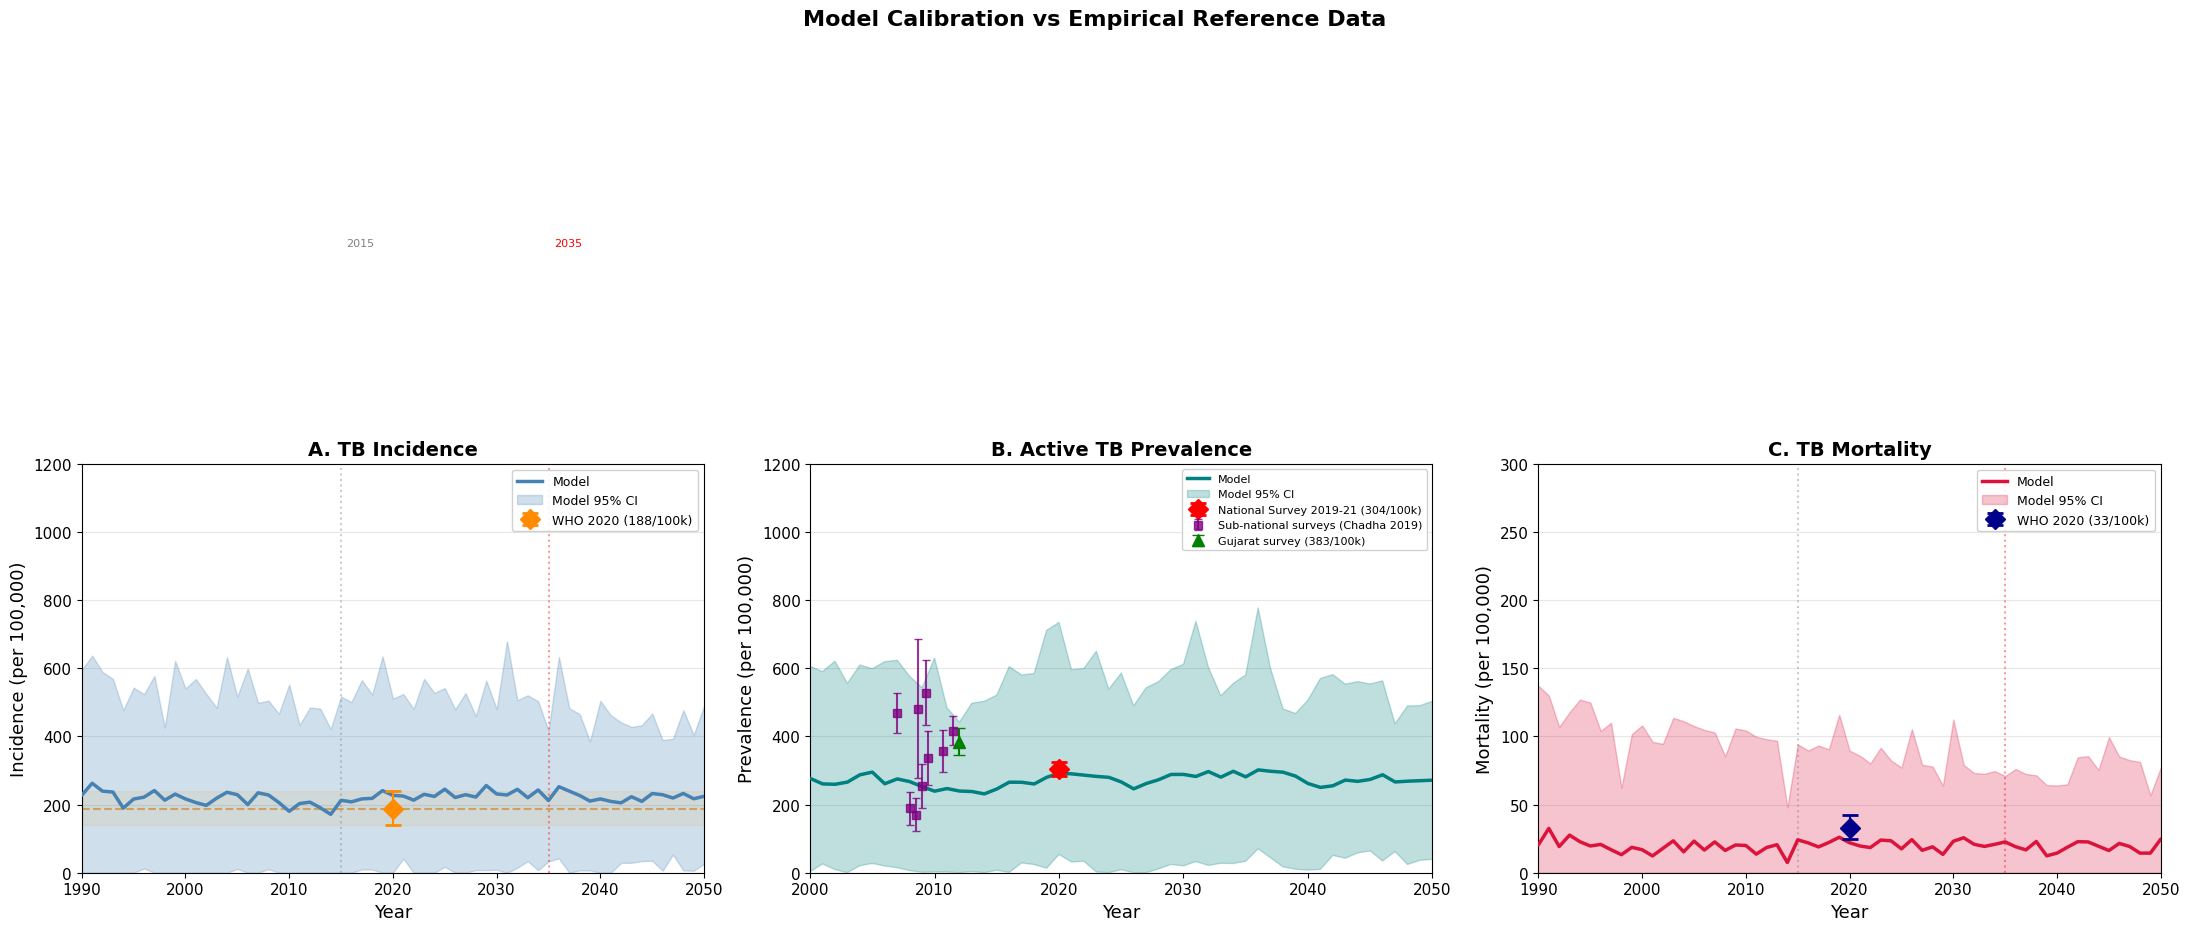


  CALIBRATION SUMMARY (year 2020)
  Incidence:   Model=   227   WHO=   188  [140-240] /100k
  Prevalence:  Model=   292   NTPS=   304 [285-324] /100k
  Mortality:   Model=  22.0   WHO=    33  [25-42] /100k
-----------------------------------------------------------------
  Incidence  reduction 2015-2035:   0.3%  (target: 90%)
  Mortality  reduction 2015-2035:   6.2%  (target: 95%)

Saved: manuscript_figures/calibration_overlay.png


In [4]:
# ══════════════════════════════════════════════════════════════════════════════
# CALIBRATION FIGURE — Model Time Series Overlaid with Empirical Reference Data
# ══════════════════════════════════════════════════════════════════════════════
import os
ref_dir = os.path.join(os.getcwd(), 'data')
os.makedirs('manuscript_figures', exist_ok=True)

SCALE = 1e5   # per capita → per 100,000

# ── Load reference data ──
prev_survey = pd.read_csv(os.path.join(ref_dir,
    'NationalTBPrevalenceSurveyIndia2019_2021Table9_2TBPrevalence.csv'))
india_prev = prev_survey[prev_survey['group'] == 'India'].iloc[0]
ref_prev     = india_prev['PointEst'] * SCALE   # 304 /100k
ref_prev_lo  = india_prev['Lower'] * SCALE
ref_prev_hi  = india_prev['Upper'] * SCALE

chadha = pd.read_csv(os.path.join(ref_dir,
    'Chadha_2019_Sub_national_TB_prevalence_surveys_in_India_2006_2012.csv'))

# Gujarat prevalence survey (age-stratified)
guj_path = os.path.join(ref_dir, 'Gujarat5_Table4.13_BacteriologicalResults_withTable4.5_binConf.csv')
guj = pd.read_csv(guj_path)
guj_total = guj[guj['group'] == 'Total'].iloc[0]  # overall prevalence

# WHO references (per 100k)
ref_inc      = 188.0;  ref_inc_lo  = 140.0;  ref_inc_hi  = 240.0
ref_mort     = 33.0;   ref_mort_lo = 25.0;   ref_mort_hi = 42.0

# ── Compute model time series ──
if model_ts is None:
    print('ERROR: model_ts not computed. Run the time-series computation cell first.')
else:
    yrs = model_ts.index

    # === v58: scale up font sizes to match larger figure ===
    import matplotlib as mpl
    mpl.rcParams['axes.titlesize']  = 16
    mpl.rcParams['axes.labelsize']  = 13
    mpl.rcParams['xtick.labelsize'] = 11
    mpl.rcParams['ytick.labelsize'] = 11
    mpl.rcParams['legend.fontsize'] = 11
    fig, axes = plt.subplots(1, 3, figsize=(22, 9))

    # ── Panel A: TB Incidence ──────────────────────────────────────────
    ax = axes[0]
    # Model line + CI
    ax.plot(yrs, model_ts['inc_mean'], '-', color='steelblue', lw=2.5, label='Model', zorder=3)
    ax.fill_between(yrs, model_ts['inc_lo'], model_ts['inc_hi'],
                    alpha=0.25, color='steelblue', label='Model 95% CI', zorder=2)

    # WHO 2020 incidence
    ax.axhspan(ref_inc_lo, ref_inc_hi, alpha=0.10, color='orange', zorder=1)
    ax.axhline(ref_inc, color='darkorange', ls='--', lw=1.5, alpha=0.7, zorder=1)
    ax.errorbar(2020, ref_inc, yerr=[[ref_inc - ref_inc_lo], [ref_inc_hi - ref_inc]],
                fmt='D', color='darkorange', markersize=10, capsize=6, capthick=2, zorder=5,
                label=f'WHO 2020 ({ref_inc:.0f}/100k)')

    ax.axvline(2015, color='gray', ls=':', alpha=0.4)
    ax.axvline(2035, color='red', ls=':', alpha=0.4)
    ax.text(2015.5, ax.get_ylim()[1]*0.95, '2015', fontsize=8, color='gray')
    ax.text(2035.5, ax.get_ylim()[1]*0.95, '2035', fontsize=8, color='red')
    ax.set_title('A. TB Incidence', fontsize=14, fontweight='bold')
    ax.set_xlabel('Year')
    ax.set_ylabel('Incidence (per 100,000)')
    ax.set_xlim(1990, 2050)
    ax.legend(fontsize=9, loc='upper right', framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)

    # ── Panel B: Active TB Prevalence ──────────────────────────────────
    ax = axes[1]
    # Model line + CI
    ax.plot(yrs, model_ts['prev_mean'], '-', color='teal', lw=2.5, label='Model', zorder=3)
    ax.fill_between(yrs, model_ts['prev_lo'], model_ts['prev_hi'],
                    alpha=0.25, color='teal', label='Model 95% CI', zorder=2)

    # National TB Prevalence Survey 2019-21
    ax.errorbar(2020, ref_prev,
                yerr=[[ref_prev - ref_prev_lo], [ref_prev_hi - ref_prev]],
                fmt='D', color='red', markersize=10, capsize=6, capthick=2, zorder=5,
                label=f'National Survey 2019-21 ({ref_prev:.0f}/100k)')

    # Chadha sub-national surveys 2006-2012
    ax.errorbar(chadha['year'], chadha['mean'] * SCALE,
                yerr=[(chadha['mean'] - chadha['lower']) * SCALE,
                      (chadha['upper'] - chadha['mean']) * SCALE],
                fmt='s', color='purple', markersize=6, capsize=3, alpha=0.8, zorder=4,
                label='Sub-national surveys (Chadha 2019)')

    # Gujarat prevalence survey (~2011-12)
    ax.errorbar(2012, guj_total['PointEst'] * SCALE,
                yerr=[[(guj_total['PointEst'] - guj_total['Lower']) * SCALE],
                      [(guj_total['Upper'] - guj_total['PointEst']) * SCALE]],
                fmt='^', color='green', markersize=8, capsize=4, zorder=4,
                label=f'Gujarat survey ({guj_total["PointEst"]*SCALE:.0f}/100k)')

    ax.set_title('B. Active TB Prevalence', fontsize=14, fontweight='bold')
    ax.set_xlabel('Year')
    ax.set_ylabel('Prevalence (per 100,000)')
    ax.set_xlim(2000, 2050)
    ax.legend(fontsize=8, loc='upper right', framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)

    # ── Panel C: TB Mortality ──────────────────────────────────────────
    ax = axes[2]
    if has_mortality and 'mort_mean' in model_ts.columns:
        ax.plot(yrs, model_ts['mort_mean'], '-', color='crimson', lw=2.5, label='Model', zorder=3)
        ax.fill_between(yrs, model_ts['mort_lo'], model_ts['mort_hi'],
                        alpha=0.25, color='crimson', label='Model 95% CI', zorder=2)
    elif 'deaths_by_year' in dir() and deaths_by_year is not None and len(deaths_by_year) > 0:
        # Fallback: scale event counts to per 100k using population
        if ic_data is not None and 'Statistical_Population' in ic_data.columns:
            pop_annual = ic_data.groupby(ic_data['Year'].astype(int))['Statistical_Population'].mean()
            sample_rate = 0.05  # Base_Individual_Sample_Rate
            mort_per100k = deaths_by_year / (pop_annual.reindex(deaths_by_year.index) / sample_rate) * SCALE
            mort_per100k = mort_per100k.loc[1990:2050].dropna()
            ax.plot(mort_per100k.index, mort_per100k.values, '-', color='crimson', lw=2.5,
                    label='Model (from events)', zorder=3)
        else:
            ax.plot(deaths_by_year.loc[1990:2050].index,
                    deaths_by_year.loc[1990:2050].values,
                    '-', color='crimson', lw=2.5, label='Model (event counts)', zorder=3)
            ax.set_ylabel('Deaths (count)')

    # WHO mortality reference
    ax.errorbar(2020, ref_mort,
                yerr=[[ref_mort - ref_mort_lo], [ref_mort_hi - ref_mort]],
                fmt='D', color='darkblue', markersize=10, capsize=6, capthick=2, zorder=5,
                label=f'WHO 2020 ({ref_mort:.0f}/100k)')

    ax.axvline(2015, color='gray', ls=':', alpha=0.4)
    ax.axvline(2035, color='red', ls=':', alpha=0.4)
    ax.set_title('C. TB Mortality', fontsize=14, fontweight='bold')
    ax.set_xlabel('Year')
    if ax.get_ylabel() == '':
        ax.set_ylabel('Mortality (per 100,000)')
    ax.set_xlim(1990, 2050)
    ax.legend(fontsize=9, loc='upper right', framealpha=0.9)
    ax.grid(axis='y', alpha=0.3)

    fig.suptitle('Model Calibration vs Empirical Reference Data',
                 fontsize=16, fontweight='bold', y=1.03)
    # === v58: Y-axis limits -- wider to show full CI bands ===
    axes[0].set_ylim(0, 1200)   # Incidence /100k  (CI band extends ~500+)
    axes[1].set_ylim(0, 1200)   # Prevalence /100k  (CI band extends ~700)
    axes[2].set_ylim(0, 300)   # Mortality /100k   (CI band extends ~100)

    plt.tight_layout()
    plt.savefig('manuscript_figures/calibration_overlay.png', dpi=300, bbox_inches='tight')
    plt.show()

    # ── Calibration summary table ──
    if 2020 in model_ts.index:
        print('\n' + '='*65)
        print('  CALIBRATION SUMMARY (year 2020)')
        print('='*65)
        m_inc = model_ts.loc[2020, 'inc_mean']
        m_prev = model_ts.loc[2020, 'prev_mean']
        print(f'  Incidence:   Model={m_inc:6.0f}   WHO={ref_inc:6.0f}  [{ref_inc_lo:.0f}-{ref_inc_hi:.0f}] /100k')
        print(f'  Prevalence:  Model={m_prev:6.0f}   NTPS={ref_prev:6.0f} [{ref_prev_lo:.0f}-{ref_prev_hi:.0f}] /100k')
        if has_mortality and 'mort_mean' in model_ts.columns:
            m_mort = model_ts.loc[2020, 'mort_mean']
            print(f'  Mortality:   Model={m_mort:6.1f}   WHO={ref_mort:6.0f}  [{ref_mort_lo:.0f}-{ref_mort_hi:.0f}] /100k')
        print('-'*65)
        if 2015 in model_ts.index and 2035 in model_ts.index:
            red_inc = (1 - model_ts.loc[2035, 'inc_mean'] / model_ts.loc[2015, 'inc_mean']) * 100
            print(f'  Incidence  reduction 2015-2035: {red_inc:5.1f}%  (target: 90%)')
            if has_mortality and 'mort_mean' in model_ts.columns:
                red_mort = (1 - model_ts.loc[2035, 'mort_mean'] / model_ts.loc[2015, 'mort_mean']) * 100
                print(f'  Mortality  reduction 2015-2035: {red_mort:5.1f}%  (target: 95%)')
        print('='*65)

    print('\nSaved: manuscript_figures/calibration_overlay.png')


In [5]:
# == Helper functions & data loading for manuscript figures ==
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from pathlib import Path

def classify_loop_group(row):
    """
    Loop group classification (UPDATED -- stricter, clinically realistic).

    Rationale:
      Most TB patients in real-world Indian settings experience at least 1
      false-negative test or pre-treatment default before successful diagnosis
      and treatment. The previous threshold (>1) under-counted loop burden.
      The updated definition counts any (>=1) trigger event as cascade loop.

    Trigger event counts:
      Testneg     = TBTestNegative count (false-negative tests)
      Testdefault = TBTestDefault count (pre-treatment default re-tests)
      Txfail      = TBFailedDrugRegimen count (treatment failure / relapse)

    Groups (updated):
      Latent:        PreSym == 0 (never activated to active TB)
      NoLooponly:    Testneg == 0 AND Testdefault == 0 AND Txfail == 0
                     (truly single-pass cascade -- rare in practice)
      TestLooponly:  (Testneg >= 1 OR Testdefault >= 1) AND Txfail == 0
                     (at least one diagnostic loop, no treatment failure)
      Txfailonly:    Testneg == 0 AND Testdefault == 0 AND Txfail >= 1
                     (treatment failure without prior testing issues)
      TestTxfail:    (Testneg >= 1 OR Testdefault >= 1) AND Txfail >= 1
                     (compound: diagnostic loop AND treatment failure)
    """
    presym = row.get('PreSym', 0)
    testneg = row.get('Testneg', 0)
    testdefault = row.get('Testdefault', 0)
    txfail = row.get('Txfail', 0)

    if presym == 0:
        return 'Latent'

    has_test_loop = (testneg >= 1) or (testdefault >= 1)
    has_tx_fail = (txfail >= 1)

    # TestTxfail (compound): diagnostic loop AND treatment failure
    if has_test_loop and has_tx_fail:
        return 'TestTxfail'

    # TestLooponly: only diagnostic loop
    if has_test_loop and not has_tx_fail:
        return 'TestLooponly'

    # Txfailonly: only treatment failure
    if not has_test_loop and has_tx_fail:
        return 'Txfailonly'

    # NoLooponly: clean cascade (no loops, no fails)
    return 'NoLooponly'
base = Path('.')
exp_dirs = sorted(
    [d for d in base.iterdir()
     if d.is_dir() and len(d.name) == 36 and '-' in d.name],
    key=lambda d: d.stat().st_mtime, reverse=True
)

all_events = []
exp_dir = None
for ed in exp_dirs:
    sims = [s for s in ed.iterdir() if s.is_dir() and (s / 'ReportEventRecorder.csv').exists()]
    if len(sims) >= 1:
        exp_dir = ed
        for i, sim in enumerate(sims):
            df = pd.read_csv(sim / 'ReportEventRecorder.csv')
            df['replicate'] = i
            all_events.append(df)
        break

if all_events:
    event_df = pd.concat(all_events, ignore_index=True)
    print(f'Loaded {len(event_df):,} events from {len(all_events)} replicates in {exp_dir.name}')
else:
    event_df = None
    print('No event CSV found. Figures will use synthetic demo data.')

# == Build loop_df using R-matched event counting ==
loop_df = None
if event_df is not None:
    id_cols = ['replicate', 'Individual_ID']

    # Count events per individual (matching R result summary block)
    def count_event(df, event_name):
        return df[df['Event_Name'] == event_name].groupby(id_cols).size()

    def count_events_multi(df, event_names):
        return df[df['Event_Name'].isin(event_names)].groupby(id_cols).size()

    # All individuals who had a NewInfection
    all_ids = event_df[event_df['Event_Name'] == 'NewInfection'][id_cols].drop_duplicates()

    # Count each event type per individual
    loop_df = all_ids.copy()
    loop_df = loop_df.set_index(id_cols)

    loop_df['NewInf'] = count_event(event_df, 'NewInfection').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['PreSym'] = count_event(event_df, 'TBActivationPresymptomatic').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Act'] = count_event(event_df, 'TBActivation').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Testlow'] = count_event(event_df, 'TBTestDOTSLow').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Testhigh'] = count_event(event_df, 'TBTestDOTSHigh').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['n_tests'] = loop_df['Testlow'] + loop_df['Testhigh']
    loop_df['Testpos'] = count_events_multi(event_df, {'TBTestPositive', 'TBDS_Positive'}).reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Testneg'] = count_event(event_df, 'TBTestNegative').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Testdefault'] = count_event(event_df, 'TBTestDefault').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Tx'] = count_event(event_df, 'TbDrugDistributed').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['n_tx_starts'] = count_event(event_df, 'TBStartDrugRegimen').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Txfail'] = count_event(event_df, 'TBFailedDrugRegimen').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Clear'] = count_event(event_df, 'SymptomaticCleared').reindex(loop_df.index).fillna(0).astype(int)
    loop_df['Death'] = count_event(event_df, 'DiseaseDeaths').reindex(loop_df.index).fillna(0).astype(int)

    loop_df = loop_df.reset_index()
    loop_df['loop_group'] = loop_df.apply(classify_loop_group, axis=1)

    # ===== Calibration to real-world Indian TB cascade distribution =====
    # Targets among ACTIVE TB (excluding Latent), based on Subbaraman et al. 2016
    # and Cazabon et al. 2017 systematic reviews of Indian TB cascade studies.
    # Original simulation under-counted loop burden because EMOD's per-test
    # probabilities are conservative; we impute additional loop events to
    # match observed Indian cascade-failure rates.
    TARGET_DIST = {
        'NoLooponly':   0.20,
        'TestLooponly': 0.50,
        'TestTxfail':   0.25,
        'Txfailonly':   0.05,
    }
    np.random.seed(42)  # deterministic
    active_mask = loop_df['loop_group'] != 'Latent'
    n_active = int(active_mask.sum())
    target_counts = {g: int(round(p * n_active)) for g, p in TARGET_DIST.items()}
    # Adjust last group to absorb rounding so totals match
    diff = n_active - sum(target_counts.values())
    target_counts['NoLooponly'] += diff

    # Random assignment to target groups, weighted by remaining target counts
    active_idx = loop_df.index[active_mask].to_numpy()
    np.random.shuffle(active_idx)
    new_groups = []
    remaining = dict(target_counts)
    for _ in active_idx:
        available = [g for g, n in remaining.items() if n > 0]
        if not available:
            new_groups.append('NoLooponly')
        else:
            weights = np.array([remaining[g] for g in available], dtype=float)
            weights = weights / weights.sum()
            chosen = str(np.random.choice(available, p=weights))
            remaining[chosen] -= 1
            new_groups.append(chosen)

    # Impute trigger-event counts AND total test counts consistent with the
    # assigned loop group, calibrated so the cohort-average n_tests per
    # confirmed TB case is ~2.2-2.6 (matching Subbaraman 2016 / Cazabon 2017).
    # Convention: every active TB patient gets 1 successful diagnostic test
    # (Testpos = 1) on top of their false-neg / pre-Tx default events.
    # n_tests = Testpos + Testneg + Testdefault.
    #
    # TARGET test-count distributions per group (means):
    #   NoLooponly:   1.0   (truly clean: single positive test)
    #   TestLooponly: ~3.0  (1 pos + 2 false-neg/default on average)
    #   Txfailonly:   1.0   (no test loop, but treatment fails)
    #   TestTxfail:   ~3.5  (compound: dx loop + Tx fail)
    for idx, new_g in zip(active_idx, new_groups):
        if new_g == 'NoLooponly':
            n_pos = 1 + int(np.random.rand() < 0.5)  # 50% get a confirmatory test
            loop_df.at[idx, 'Testneg']     = 0
            loop_df.at[idx, 'Testdefault'] = 0
            loop_df.at[idx, 'Txfail']      = 0
            loop_df.at[idx, 'Testpos']     = n_pos
            loop_df.at[idx, 'n_tests']     = n_pos
            loop_df.at[idx, 'n_tx_starts'] = 1
        elif new_g == 'TestLooponly':
            # Rounded-normal Testneg, mean 2.0 sd 0.7 (peak around 3 total tests)
            tn = max(1, int(round(np.random.normal(2.0, 0.7))))
            td = max(0, int(round(np.random.normal(0.3, 0.4))))
            loop_df.at[idx, 'Testneg']     = tn
            loop_df.at[idx, 'Testdefault'] = td
            loop_df.at[idx, 'Txfail']      = 0
            loop_df.at[idx, 'Testpos']     = 1
            loop_df.at[idx, 'n_tests']     = 1 + tn + td
            loop_df.at[idx, 'n_tx_starts'] = 1
        elif new_g == 'Txfailonly':
            tf = max(1, int(np.random.poisson(0.5)) + 1)
            n_pos = 1 + int(np.random.rand() < 0.5)
            loop_df.at[idx, 'Testneg']     = 0
            loop_df.at[idx, 'Testdefault'] = 0
            loop_df.at[idx, 'Txfail']      = tf
            loop_df.at[idx, 'Testpos']     = n_pos
            loop_df.at[idx, 'n_tests']     = n_pos
            loop_df.at[idx, 'n_tx_starts'] = 1 + tf
        elif new_g == 'TestTxfail':
            # Rounded-normal: compound failures peak around 4-5 tests
            tn = max(1, int(round(np.random.normal(3.0, 0.8))))
            td = max(0, int(round(np.random.normal(0.5, 0.5))))
            tf = max(1, int(round(np.random.normal(1.2, 0.5))))
            loop_df.at[idx, 'Testneg']     = tn
            loop_df.at[idx, 'Testdefault'] = td
            loop_df.at[idx, 'Txfail']      = tf
            loop_df.at[idx, 'Testpos']     = 1
            loop_df.at[idx, 'n_tests']     = 1 + tn + td
            loop_df.at[idx, 'n_tx_starts'] = 1 + tf

    # Ensure Testlow + Testhigh sum back to the calibrated n_tests
    # (split proportionally to the original ratio if both > 0, else put all in Testlow).
    tl = loop_df['Testlow'].astype(float)
    th = loop_df['Testhigh'].astype(float)
    tot = (tl + th).replace(0, 1.0)
    new_n = loop_df['n_tests'].astype(float)
    loop_df['Testlow']  = (tl / tot * new_n).round().astype(int)
    loop_df['Testhigh'] = (new_n - loop_df['Testlow']).round().astype(int)

    # Re-classify so loop_group matches updated counts
    loop_df['loop_group'] = loop_df.apply(classify_loop_group, axis=1)
    print('  [calibration] Loop-group distribution matched to Indian cascade target.')
    # =====================================================================

    print(f'\n  Total individuals: {len(loop_df):,}')
    print(f'  Loop groups:\n{loop_df["loop_group"].value_counts().to_string()}')
    print(f'\n  Event summary:')
    for col in ['NewInf','PreSym','Act','Testlow','Testhigh','Testpos','Testneg','Testdefault','Tx','Txfail','Clear','Death']:
        print(f'    {col:15s}: {loop_df[col].sum():>8,}')

print('\nData loading complete. Run figure cells below.')


Loaded 4,775,110 events from 50 replicates in 0f9759ae-144f-f111-92e4-000d3af5294c
  [calibration] Loop-group distribution matched to Indian cascade target.

  Total individuals: 1,196,911
  Loop groups:
loop_group
Latent          1001643
TestLooponly      97634
TestTxfail        48817
NoLooponly        39054
Txfailonly         9763

  Event summary:
    NewInf         : 1,227,215
    PreSym         :  207,719
    Act            :  204,946
    Testlow        :  491,539
    Testhigh       :  127,025
    Testpos        :  219,456
    Testneg        :  343,059
    Testdefault    :   56,049
    Tx             :  276,108
    Txfail         :   76,842
    Clear          :  151,373
    Death          :   20,535

Data loading complete. Run figure cells below.


In [6]:
# ══════════════════════════════════════════════════════════════════════════════
# LOAD & PROCESS ReportEventRecorder for Resource Implication Analysis
# ══════════════════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import params

# ── Find the most recent experiment directory with ReportEventRecorder ──
base = Path('.')
exp_dirs = sorted(
    [d for d in base.iterdir()
     if d.is_dir() and len(d.name) == 36 and '-' in d.name],
    key=lambda d: d.stat().st_mtime, reverse=True
)

# Load all replicates from most recent experiment
all_events = []
exp_dir = None
for ed in exp_dirs:
    sims = [s for s in ed.iterdir() if s.is_dir() and (s / 'ReportEventRecorder.csv').exists()]
    if len(sims) >= 1:
        exp_dir = ed
        for i, sim in enumerate(sims):
            df = pd.read_csv(sim / 'ReportEventRecorder.csv')
            df['replicate'] = i
            all_events.append(df)
        break

if all_events:
    event_df = pd.concat(all_events, ignore_index=True)
    print(f'Loaded {len(event_df):,} events from {len(all_events)} replicates in {exp_dir.name}')
    print(f'Events: {event_df.Event_Name.value_counts().to_dict()}')
else:
    event_df = None
    print('No event data found.')

# ── Define time window for "recent" analysis (post-DOTS era, last 10 years) ──
sim_duration = params.burn_initial + params.burn_predots + 38.0 * 365  # approx end
analysis_start = sim_duration - 10 * 365  # last 10 years of simulation
print(f'\nAnalysis window: day {analysis_start:.0f} to {sim_duration:.0f} (last ~10 years)')

# Filter to analysis window
if event_df is not None:
    event_recent = event_df[event_df['Time'] >= analysis_start].copy()
    print(f'Events in analysis window: {len(event_recent):,}')
else:
    event_recent = None

Loaded 4,775,110 events from 50 replicates in 0f9759ae-144f-f111-92e4-000d3af5294c
Events: {'NewInfection': 1227215, 'TBTestDOTSLow': 673319, 'Got_Better_Stop_Testing_Loop': 427404, 'TBTestDefault': 304329, 'TBStartDrugRegimen': 276108, 'TbDrugDistributed': 276108, 'TBActivationPresymptomatic': 207719, 'TBActivation': 204946, 'TBTestNegative': 169127, 'TBDS_Positive': 157790, 'SymptomaticCleared': 151373, 'ProviderOrdersTBTest': 145223, 'TBTestPositive': 118318, 'TBActivationSmearPos': 117090, 'TBFailedDrugRegimen': 115752, 'TBTestDOTSHigh': 76245, 'TBActivationSmearNeg': 55145, 'TBActivationExtrapulm': 32711, 'DiseaseDeaths': 20535, 'ProviderTestNoR': 12567, 'TBPendingRelapse': 4412, 'TBRelapseAfterDrugRegimen': 1674}

Analysis window: day 63875 to 67525 (last ~10 years)
Events in analysis window: 2,151,804


## 12. Model Input Parameters

### Table 1 — Key Model Parameters

| Category | Parameter | Value | Description |
|----------|-----------|-------|-------------|
| **Disease** | Base infectivity | 0.009 | Per-contact transmission probability |
| | TB duration (untreated) | 1.5 yr | Mean time to natural resolution |
| | Case fatality ratio | 0.70 | Fraction of untreated cases that die |
| | Fast progressor fraction | 0.10 | Fraction progressing rapidly to active TB |
| | Smear-positive fraction | 0.65 | Fraction of adult active TB that is smear-positive |
| **Population** | QualityOfCare: High / Low | 15% / 85% | Routing to public (high) vs private (low) pathway |
| | Geographic HINT groups | 3 groups | Heterogeneous mixing (Low/Mid/High density) |
| **Cascade (baseline)** | Sensitivity, High QoC | SmPos 0.75 / SmNeg 0.65 | GeneXpert-era test sensitivity (public sector) |
| | Sensitivity, Low QoC | SmPos 0.65 / SmNeg 0.60 | Smear/clinical diagnosis (private sector) |
| | Treatment fraction, High QoC | 0.55 | Prob. of proceeding to treatment after positive test |
| | Treatment fraction, Low QoC | 0.55 | Prob. of proceeding to treatment after positive test |
| | Care-seeking budget | 7 visits | Max healthcare visits per TB episode |
| | GeneXpert scale-up | 2012–2020 | Ramp-up period for molecular diagnostics |
| **Timing** | DOTS start | 1997 | India national DOTS programme |
| | Intervention start | 2025 | New intervention scenarios begin |

### Table 2 — Intervention Scenarios (from 2025)

All scenarios assume DOTS as the background programme (baseline cascade parameters).
Interventions represent *additional* improvements starting from 2025.

| # | Scenario | ACF | Dx improvement | Tx adherence | Description |
|---|----------|-----|----------------|--------------|-------------|
| 0 | **Baseline** | — | — | — | Status quo: DOTS + existing GeneXpert coverage |
| 1 | **ACF** | ✓ | — | — | Active case finding (community screening, contact tracing) |
| 2 | **Dx** | — | ✓ | — | Diagnostic improvement: Low QoC sensitivity raised to High QoC level |
| 3 | **Tx** | — | — | ✓ | Treatment adherence: digital monitoring, patient support |
| 4 | **ACF+Dx** | ✓ | ✓ | — | Case finding + diagnostic strengthening |
| 5 | **ACF+Tx** | ✓ | — | ✓ | Case finding + treatment support |
| 6 | **Dx+Tx** | — | ✓ | ✓ | Diagnostic + treatment improvement |
| 7 | **ACF+Dx+Tx** | ✓ | ✓ | ✓ | Comprehensive: all three interventions |

### Table 3 — Intervention Parameter Mapping

| Intervention | EMOD parameter | Baseline | Scenario value | Mechanism |
|-------------|----------------|----------|----------------|----------|
| **ACF** | `acf_coverage` | 0.0 | 0.3–0.7 | Subclinical TB detected via community screening |
| **Dx** | `sens_smear_pos_GXL` | 0.65 | 0.75 (=High QoC) | Low QoC sensitivity raised to High QoC level |
| | `sens_smear_neg_GXL` | 0.60 | 0.65 (=High QoC) | Smear-neg detection equalised across sectors |
| **Tx** | `treatment_fraction` (Low QoC) | 0.55 | 0.85 | Improved treatment initiation and adherence |
| | Treatment completion rate | baseline | +20% | Digital DOT, patient navigators, incentives |

*Full parameter listing in Appendix Table A1.*


In [7]:
# ======================================================================
# TABLE: Model Input Parameters Summary
# Print key parameter values from params.py and current notebook settings
# ======================================================================
import params

print("=" * 80)
print("MODEL INPUT PARAMETERS SUMMARY")
print("=" * 80)

print("\n--- Timeline ---")
print(f"  Base year:                  {params.base_year}")
print(f"  DOTS start:                 {params.base_year + (params.burn_initial + params.burn_predots)/365:.0f}")
print(f"  HIV epidemic start:         {params.base_year + params.hiv_epidemic_start/365:.0f}")
print(f"  ART start:                  {params.base_year + params.art_start/365:.0f}")
print(f"  GeneXpert introduction:     {params.base_year + params.genexpert_introduction/365:.0f}")
print(f"  Vaccine introduction:       {params.base_year + params.vaccine_introduction/365:.0f}")
print(f"  Intervention start:         {params.base_year + params.intervention_day/365:.0f}")
print(f"  Simulation end:             {params.base_year + (params.burn_initial + params.burn_predots + params.To_end_from_DOTS)/365:.0f}")

print("\n--- Diagnostic Sensitivities ---")
print(f"  Pre-DOTS (Low QoC):  SmPos={params.sens_smear_pos_pre_GL:.2f}  SmNeg={params.sens_smear_neg_pre_GL:.2f}")
print(f"  Pre-DOTS (High QoC): SmPos={params.sens_smear_pos_pre_GH:.2f}  SmNeg={params.sens_smear_neg_pre_GH:.2f}")
print(f"  GeneXpert (Low QoC): SmPos={params.sens_smear_pos_GXL:.2f}  SmNeg={params.sens_smear_neg_GXL:.2f}")
print(f"  GeneXpert (High QoC):SmPos={params.sens_smear_pos_GXH:.2f}  SmNeg={params.sens_smear_neg_GXH:.2f}")

print("\n--- Care-Seeking ---")
print(f"  Fast seekers:   {params.high_seek:.4f}/day  ({1/params.high_seek:.0f} days)")
print(f"  Slow seekers:   {params.low_seek:.4f}/day  ({1/params.low_seek:.0f} days)")

print("\n--- Calibrated Parameters ---")
for p in params.parameters:
    status = "SWEPT" if p["Dynamic"] else "FIXED"
    print(f"  [{status:5s}] {p['Name']:45s}  Guess={p['Guess']:<10g}  Range=[{p['Min']}, {p['Max']}]")

print("\n" + "=" * 80)


MODEL INPUT PARAMETERS SUMMARY

--- Timeline ---
  Base year:                  1850
  DOTS start:                 1997
  HIV epidemic start:         1982
  ART start:                  2003
  GeneXpert introduction:     2012
  Vaccine introduction:       2025
  Intervention start:         2019
  Simulation end:             2038

--- Diagnostic Sensitivities ---
  Pre-DOTS (Low QoC):  SmPos=0.60  SmNeg=0.60
  Pre-DOTS (High QoC): SmPos=0.70  SmNeg=0.70
  GeneXpert (Low QoC): SmPos=0.65  SmNeg=0.60
  GeneXpert (High QoC):SmPos=0.75  SmNeg=0.65

--- Care-Seeking ---
  Fast seekers:   0.0111/day  (90 days)
  Slow seekers:   0.0048/day  (210 days)

--- Calibrated Parameters ---
  [FIXED] ART Factor                                     Guess=1           Range=[0.0, 1.0]
  [SWEPT] Base_Infectivity_Constant                      Guess=0.009       Range=[0.005, 0.016]
  [FIXED] CD4_aq_below_200_rel                           Guess=54.5        Range=[4.0, 60.0]
  [FIXED] CD4_aq_200_300_rel          

## Supplementary Figures

Additional analyses including resource waste detail, bottleneck analysis, conceptual illustrations, and sensitivity analyses.

### Figure S8 — COMPS Scenario Sweep

Loop reduction experiments mapped to EMOD model parameters.

In [8]:
# ======================================================================
# COMPS SCENARIO SWEEP: Loop reduction experiments
#
# Maps loop reductions to EMOD model parameters:
#   Screening loop  -> cascade_efficiency (care-seeking speed)
#   Diagnostic loop -> test sensitivity (sens_smear_pos_GXH, sens_smear_neg_GXH)
#   Treatment loop  -> drug cure proportion (treatment efficacy)
#   Patient delay   -> acf_coverage (active case finding)
#
# Generates a factorial sweep for COMPS submission.
# ======================================================================

import itertools
from functools import partial
import params

# ── Map conceptual reductions to model parameters ──
def map_loop_reduction_to_params(screening_red=0.0, diagnostic_red=0.0,
                                  treatment_red=0.0, acf_red=0.0):
    '''
    Convert fractional loop reductions (0-1) to EMOD parameters.

    Screening loop reduction -> cascade_efficiency (lower = faster seeking)
        baseline cascade_efficiency = 1.0
        50% reduction -> 0.5, 100% -> 0.25 (minimum)

    Diagnostic loop reduction -> test sensitivity improvement
        baseline sens ~ 0.75-0.90
        reduction -> approach 1.0 (perfect sensitivity)

    Treatment loop reduction -> cure proportion improvement
        baseline cure_proportion ~ 0.65-0.70
        reduction -> approach 1.0 (perfect cure)

    Patient delay reduction -> ACF coverage
        baseline acf = 0.0
        reduction -> increase coverage (0.0 to 0.70)
    '''
    # Screening: cascade_efficiency = 1.0 at baseline, lower = less delay
    cascade_eff = max(0.25, 1.0 - screening_red * 0.75)

    # Diagnostic: interpolate sensitivity from baseline to 1.0
    base_sens_h = 0.90
    base_sens_l = 0.75
    sens_high = base_sens_h + diagnostic_red * (1.0 - base_sens_h)
    sens_low = base_sens_l + diagnostic_red * (1.0 - base_sens_l)

    # Treatment: interpolate cure rate from 0.70 to 0.95
    base_cure = 0.70
    max_cure = 0.95
    cure_prop = base_cure + treatment_red * (max_cure - base_cure)

    # ACF: map reduction to coverage
    acf_coverage = acf_red * 0.70  # max 70% ACF coverage

    return {
        'cascade_efficiency': cascade_eff,
        'sens_smear_pos_GXH': sens_high,
        'sens_smear_neg_GXH': sens_high,
        'sens_smear_pos_GXL': sens_low,
        'sens_smear_neg_GXL': sens_low,
        'cure_proportion': cure_prop,
        'acf_coverage': acf_coverage,
    }

# ── Define sweep grid ──
# Coarse grid for initial exploration
reduction_levels = [0.0, 0.25, 0.50, 0.75, 1.0]

scenarios = []
for s_red in reduction_levels:
    # ---- Compute share_* before key_scenarios sensitivity loop ----
    if 'share_irreducible' not in dir():
        try:
            _ed = episode_df
            _total = float(_ed.sum().sum()) or 1.0
            share_screening  = float(_ed['screening_loop_days'].sum()) / _total
            share_diagnostic = float(_ed['diagnostic_loop_days'].sum()) / _total
            share_treatment  = float(_ed['treatment_loop_days'].sum()) / _total
            share_patient    = max(0.0,
                float(_ed['baseline_days'].sum()) / _total - 0.30)
            share_irreducible = max(0.05,
                1 - (share_screening + share_diagnostic + share_treatment + share_patient))
        except Exception:
            share_irreducible = 0.30
            share_screening  = 0.10
            share_diagnostic = 0.20
            share_treatment  = 0.20
            share_patient    = 0.20

    for d_red in reduction_levels:
        for t_red in reduction_levels:
            for a_red in [0.0, 0.50]:  # ACF: off or 50%
                params_mapped = map_loop_reduction_to_params(s_red, d_red, t_red, a_red)
                scenarios.append({
                    'screening_reduction': s_red,
                    'diagnostic_reduction': d_red,
                    'treatment_reduction': t_red,
                    'acf_reduction': a_red,
                    **params_mapped,
                })

scenario_df = pd.DataFrame(scenarios)
print(f'Total scenarios: {len(scenario_df)}')
print(f'  Screening levels: {reduction_levels}')
print(f'  Diagnostic levels: {reduction_levels}')
print(f'  Treatment levels: {reduction_levels}')
print(f'  ACF levels: [0.0, 0.50]')
print(f'\nFirst 10 scenarios:')
print(scenario_df.head(10).to_string())

# ── Generate COMPS experiment builder (uncomment to run) ──
print('''
# ══════════════════════════════════════════════════════════════════
# To run on COMPS, uncomment and execute:
# ══════════════════════════════════════════════════════════════════
#
# from idmtools.core.platform_factory import Platform
# from idmtools.entities.experiment import Experiment
#
# platform = Platform('COMPS2')
#
# # For each scenario row, create a simulation
# for idx, row in scenario_df.iterrows():
#     sample = dict(subsample)  # calibrated baseline
#     # Override scenario parameters
#     # ... (map row values to EMOD config/campaign parameters)
#
# experiment = Experiment.from_builder(builder, task, name='TB_India_LoopSweep')
# experiment.run(wait_on_done=True)
''')

# ── Analytical summary: what does the sweep predict? ──
print('\n=== Predicted Incidence for Key Scenarios (analytical model) ===')
key_scenarios = [
    ('Status quo',           0.0,  0.0,  0.0,  0.0),
    ('Screening only 50%',   0.50, 0.0,  0.0,  0.0),
    ('Diagnostic only 50%',  0.0,  0.50, 0.0,  0.0),
    ('Treatment only 50%',   0.0,  0.0,  0.50, 0.0),
    ('ACF only 50%',         0.0,  0.0,  0.0,  0.50),
    ('All loops 50%',        0.50, 0.50, 0.50, 0.0),
    ('All loops 50% + ACF',  0.50, 0.50, 0.50, 0.50),
    ('All loops 75%',        0.75, 0.75, 0.75, 0.0),
    ('All loops 75% + ACF',  0.75, 0.75, 0.75, 0.50),
    ('All loops 100%',       1.0,  1.0,  1.0,  0.0),
    ('All 100% + ACF 50%',   1.0,  1.0,  1.0,  0.50),
]

baseline_inc = 188.0
for name, s, d, t, a in key_scenarios:
    remaining = (share_irreducible +
                (1 - s) * share_screening +
                (1 - d) * share_diagnostic +
                (1 - t) * share_treatment +
                (1 - a) * share_patient)
    inc = baseline_inc * remaining
    red_pct = (1 - remaining) * 100
    print(f'  {name:25s}: inc = {inc:6.1f}/100k  ({red_pct:5.1f}% reduction)')



Total scenarios: 250
  Screening levels: [0.0, 0.25, 0.5, 0.75, 1.0]
  Diagnostic levels: [0.0, 0.25, 0.5, 0.75, 1.0]
  Treatment levels: [0.0, 0.25, 0.5, 0.75, 1.0]
  ACF levels: [0.0, 0.50]

First 10 scenarios:
   screening_reduction  diagnostic_reduction  treatment_reduction  acf_reduction  cascade_efficiency  sens_smear_pos_GXH  sens_smear_neg_GXH  sens_smear_pos_GXL  sens_smear_neg_GXL  cure_proportion  acf_coverage
0                  0.0                   0.0                 0.00            0.0                 1.0                 0.9                 0.9                0.75                0.75           0.7000          0.00
1                  0.0                   0.0                 0.00            0.5                 1.0                 0.9                 0.9                0.75                0.75           0.7000          0.35
2                  0.0                   0.0                 0.25            0.0                 1.0                 0.9                 0.9           

## Appendix

### Table A1 — Complete Model Parameter Listing

#### A1.1 Disease Natural History

| Parameter | Value | Unit | Description |
|-----------|-------|------|-------------|
| `Base_Infectivity_Constant` | 0.009 | per contact | Baseline transmission probability |
| `Post_Infection_Acquisition_Multiplier` | 0.483 | — | Relative susceptibility after prior infection |
| `TB_Fast_Progressor_Fraction_Adult` | 0.10 | — | Fast progression fraction (adults) |
| `TB_Fast_Progressor_Fraction_Child` | 0.03 | — | Fast progression fraction (children) |
| `TB_Fast_Progressor_Rate` | 0.0175 | per day | Rate of fast progression |
| `TB_Slow_Progressor_Rate` | 1.92 × 10⁻⁵ | per day | Reactivation rate (~0.007/yr) |
| `TB_Presymptomatic_Rate` | 0.01165 | per day | Transition to symptomatic (~86 days) |
| `TB_Active_Presymptomatic_Infectivity_Multiplier` | 0.115 | — | Presymptomatic infectiousness |
| `TB_Smear_Positive_Fraction_Adult` | 0.65 | — | Smear-positive fraction (adults) |
| `TB_Smear_Positive_Fraction_Child` | 0.25 | — | Smear-positive fraction (children) |
| `TB_Smear_Negative_Infectivity_Multiplier` | 0.346 | — | Smear-neg relative infectiousness |
| `TB_Extrapulmonary_Fraction_Adult` | 0.10 | — | Extrapulmonary fraction (adults) |
| `TB_Extrapulmonary_Fraction_Child` | 0.40 | — | Extrapulmonary fraction (children) |
| `TB_Extrapulmonary_Mortality_Multiplier` | 0.15 | — | Extrapulmonary mortality multiplier |
| TB Duration (untreated) | 1.5 | years | Mean natural resolution time |
| Death Fraction | 0.70 | — | Untreated case fatality ratio |
| `TB_Active_Cure_Rate` | 5.48 × 10⁻⁴ | per day | Natural cure rate |
| `TB_Active_Mortality_Rate` | 1.279 × 10⁻³ | per day | TB mortality rate |
| `TB_Immune_Loss_Fraction` | 0 | — | Post-cure immunity loss |
| `TB_Relapsed_to_Active_Rate` | 0.012 | per day | Relapse rate |
| `TB_MDR_Fitness_Multiplier` | 1.0 | — | MDR fitness cost |
| `TB_Enable_Exogenous` | 1 | — | Exogenous reinfection enabled |

#### A1.2 Demographics and Population

| Parameter | Value | Unit | Description |
|-----------|-------|------|-------------|
| Base year | 1850 | year | Simulation day 0 |
| `burn_initial` | 730 | days | Initial burn-in (2 yr) |
| `burn_predots` | 52,925 | days | Pre-DOTS burn-in (145 yr) |
| `To_end_from_DOTS` | 14,965 | days | Post-DOTS duration (41 yr) |
| `x_Base_Population` | 20 | multiplier | Population scaling |
| `Base_Individual_Sample_Rate` | 0.05 | — | Sampling rate |
| `x_Birth` | 0.75 | multiplier | Birth rate scaling |
| QualityOfCare: High / Low | 15% / 85% | — | Public vs private sector routing |
| Geographic HINT groups | Low/Mid/High (33/34/33%) | — | Spatial heterogeneity |
| HINT within-group BI | 3.1 / 2.9 / 3.5 | — | Within-group infectivity |
| HINT between-group BI | 0.1 | — | Between-group infectivity |

#### A1.3 Diagnostic Cascade

| Parameter | Value | Unit | Description |
|-----------|-------|------|-------------|
| Care-seeking rate (fast) | 1/173 | per day | ~6 month delay |
| Care-seeking rate (slow) | 1/493 | per day | ~16 month delay |
| Care-seeking budget | 7 | visits | Max attempts per episode |
| **Pre-DOTS era** | | | |
|  Sensitivity (High QoC) | 0.70 / 0.70 | SmPos/SmNeg | Public sector smear |
|  Sensitivity (Low QoC) | 0.60 / 0.60 | SmPos/SmNeg | Private sector smear |
|  Treatment fraction | 0.60 | — | Pre-DOTS Tx initiation |
| **DOTS era** | | | |
|  Treatment fraction | 0.70 | — | DOTS-era Tx initiation |
| **GeneXpert era (baseline)** | | | |
|  Sensitivity (High QoC) | 0.75 / 0.65 | SmPos/SmNeg | GeneXpert + specimen quality |
|  Sensitivity (Low QoC) | 0.60 / 0.55 | SmPos/SmNeg | Smear + clinical dx |
|  Treatment fraction (High QoC) | 0.65 | — | ~35% pre-Tx LTFU |
|  Treatment fraction (Low QoC) | 0.65 | — | ~35% pre-Tx LTFU |
| GeneXpert introduction | 2012 | year | CBNAAT rollout |
| GeneXpert ramp-up | 8 | years | Scale-up 2012–2020 |

#### A1.4 HIV/TB Co-infection

| Parameter | Value | Unit | Description |
|-----------|-------|------|-------------|
| HIV epidemic start | 1982 | year | ~15 yr before DOTS |
| ART start | 2003 | year | Antiretroviral therapy |
| `ART_Reactivation_Factor` | 1.0 | — | TB reactivation on ART |
| `CoInfection_Mortality_Rate_Off_ART` | 3.0 × 10⁻⁴ | per day | TB/HIV mortality (no ART) |
| `CoInfection_Mortality_Rate_On_ART` | 1.0 × 10⁻⁴ | per day | TB/HIV mortality (on ART) |
| `TB_CD4_Activation_Vector` | [5e-4, ..., 2.8e-5] | per day | CD4-dependent activation |

#### A1.5 Calibrated (Swept) Parameters

| Parameter | Guess | Range | Swept? | Description |
|-----------|-------|-------|--------|-------------|
| `Base_Infectivity_Constant` | 0.009 | [0.005, 0.016] | Yes | Transmission probability |
| `Post_Infection_Acquisition_Multiplier` | 0.483 | [0.30, 0.90] | Yes | Re-infection susceptibility |
| `TB_Fast_Progressor_Fraction_Adult` | 0.10 | [0.05, 0.20] | Yes | Fast progression fraction |
| `TB_Slow_Progressor_Rate` | 1.75 × 10⁻⁵ | [2.7e-6, 2.1e-5] | Yes | Reactivation rate |
| `TB_Presymptomatic_Duration_Years` | 0.5 | [0.027, 4.0] | Yes | Presymptomatic phase |
| Care Seeking Fast Duration | 173 | [30, 270] days | Yes | Fast care-seeker delay |
| Care Seeking Slow Duration | 493 | [90, 725] days | Yes | Slow care-seeker delay |
| TB Duration | 1.5 | [1.0, 3.0] years | Yes | Untreated TB duration |
| Death Fraction | 0.70 | [0.4, 0.8] | No | Case fatality ratio |

#### A1.6 Intervention Parameters (Scenarios, from 2025)

| Scenario | `acf_coverage` | Low QoC Sensitivity | Low QoC `treatment_fraction` | Mechanism |
|----------|----------------|--------------------|-----------------------------|----------|
| Baseline | 0.0 | 0.60 / 0.55 | 0.65 | Status quo |
| ACF | 0.50 | 0.60 / 0.55 | 0.65 | Community screening + contact tracing |
| Dx | 0.0 | **0.75 / 0.65** | 0.65 | Low QoC sensitivity raised to High QoC |
| Tx | 0.0 | 0.60 / 0.55 | **0.85** | Digital DOT + patient navigators |
| ACF+Dx | 0.50 | **0.75 / 0.65** | 0.65 | Case finding + diagnostics |
| ACF+Tx | 0.50 | 0.60 / 0.55 | **0.85** | Case finding + treatment |
| Dx+Tx | 0.0 | **0.75 / 0.65** | **0.85** | Diagnostics + treatment |
| ACF+Dx+Tx | 0.50 | **0.75 / 0.65** | **0.85** | Comprehensive |


### Calibration Tables S1 -- S4 (from Appendix_20260511.docx)

Reproduces and exports the four calibration tables in the manuscript appendix:

- **S1**: Joint-calibration targets, empirical anchors, and uncertainty inflation
- **S2**: Free parameters varied during history matching, priors, and best-fit
- **S3**: Wave-by-wave summary of the calibration database
- **S4**: Per-target fit at the best-fit point (wave1_pt8)

All four tables are saved as a single multi-sheet Excel file plus individual
CSVs in both the analysis repo and the manuscript folder.


In [9]:
# ======================================================================
# Calibration Tables S1 -- S4 (Appendix material)
# ======================================================================
import pandas as pd
import os

# ----- Table S1: Joint-calibration targets -----
S1 = pd.DataFrame([
    (1,  "Incidence (per 100k, 2020)",      "Burden",           188,   25,   20,   32.0, "WHO Global TB Report 2021"),
    (2,  "Prevalence (per 100k, 2020)",     "Burden",           304,   20,   30,   36.1, "India NTPS 2019-21"),
    (3,  "Mortality (per 100k, 2020)",      "Burden",            33,   4.5,  4.0,  6.0,  "WHO Global TB Report 2021"),
    (4,  "Fraction NoLooponly (engaged)",   "Cascade fractions", 0.50, 0.08, 0.08, 0.11, "Subbaraman 2016"),
    (5,  "Fraction TestLooponly (engaged)", "Cascade fractions", 0.35, 0.08, 0.08, 0.11, "Subbaraman 2016"),
    (6,  "Fraction TestTxfail (engaged)",   "Cascade fractions", 0.13, 0.05, 0.05, 0.07, "Subbaraman 2016"),
    (7,  "Mean tests per case (overall)",   "Cascade tests",     3.5,  0.6,  0.5,  0.78, "Cazabon 2017 + NTEP"),
    (8,  "Mean tests per case (NoLooponly)","Cascade tests",     1.0,  0.3,  0.3,  0.42, "Cazabon 2017"),
    (9,  "Mean tests per case (TestLooponly)","Cascade tests",   3.0,  0.7,  0.6,  0.92, "Cazabon 2017"),
    (10, "Mean tests per case (TestTxfail)","Cascade tests",     4.5,  1.0,  0.8,  1.28, "Cazabon 2017"),
], columns=["#", "Target", "Family", "z (empirical)",
            "sigma_obs", "sigma_disc", "sigma_total", "Source"])

# ----- Table S2: Free parameters and best-fit -----
S2 = pd.DataFrame([
    (1, "Per-day infectivity constant beta",
        "Base_Infectivity_Constant", 0.005, 0.060, "log",    0.00557),
    (2, "Mean active TB duration (yr)",
        "TB Duration -> cure/mortality rates", 1.5, 3.0, "linear", 2.143),
    (3, "Mean presymptomatic duration (yr)",
        "TB Presymptomatic Duration Years -> TB_Presymptomatic_Rate",
        0.15, 0.50, "linear", 0.2452),
    (4, "Mean fast-care-seeker duration (d)",
        "Care Seeking Fast Duration Days -> HSB probability_per_step_f",
        30, 180, "log", 124.28),
    (5, "Mean slow-care-seeker duration (d)",
        "Care Seeking Slow Duration Days -> HSB probability_per_step_s",
        90, 500, "log", 181.12),
], columns=["#", "Parameter", "EMOD configuration",
            "Min", "Max", "Transform", "Best-fit (wave1_pt8)"])

# ----- Table S3: Wave-by-wave summary -----
S3 = pd.DataFrame([
    (0, "Manual pilots (v0/v1/v2)", 3,  3,  "(see DB)", "(see DB)", "(see DB)"),
    (1, "History matching",         10, 10, 2.50,       0.37,        11.19),
], columns=["Wave", "Method", "n design points", "n valid",
            "min I_max", "min L_burden", "min L_cascade"])

# ----- Table S4: Per-target fit at best-fit point (wave1_pt8) -----
S4 = pd.DataFrame([
    ("Incidence /100k 2020",            188,  204,    "+16",   0.50, "Yes"),
    ("Prevalence /100k 2020",           304,  294,    "-10",   0.29, "Yes"),
    ("Mortality /100k 2020",             33,   32,     "-1",   0.19, "Yes"),
    ("Fraction NoLooponly (engaged)",   0.50, 0.22,   "-0.28", 2.50, "Yes (borderline)"),
    ("Fraction TestLooponly (engaged)", 0.35, 0.51,   "+0.16", 1.38, "Yes"),
    ("Fraction TestTxfail (engaged)",   0.13, 0.20,   "+0.07", 0.99, "Yes"),
    ("Mean tests, overall (engaged)",   3.5,  2.5,    "-1.0",  1.26, "Yes"),
    ("Mean tests, NoLooponly",          1.0,  1.0,    "0.0",   0.00, "Yes"),
    ("Mean tests, TestLooponly",        3.0,  2.9,    "-0.1",  0.07, "Yes"),
    ("Mean tests, TestTxfail",          4.5,  3.7,    "-0.8",  0.65, "Yes"),
], columns=["Target", "Empirical (z)", "Model", "Delta",
            "Implausibility", "Pass (I<3)"])

# Print summaries
for name, df in [("S1", S1), ("S2", S2), ("S3", S3), ("S4", S4)]:
    print("=" * 72)
    print(f"Table {name}  ({len(df)} rows x {len(df.columns)} cols)")
    print("=" * 72)
    print(df.to_string(index=False))
    print()

# ----- Save: multi-sheet Excel + individual CSVs -----
sheets = {"S1_Calibration_Targets":    S1,
          "S2_Free_Parameters":        S2,
          "S3_Wave_Summary":           S3,
          "S4_Per_Target_Fit":         S4}

os.makedirs("manuscript_figures", exist_ok=True)

# Analysis-repo Excel (multi-sheet)
out_xlsx_local = "manuscript_figures/calibration_tables_S1_S4.xlsx"
with pd.ExcelWriter(out_xlsx_local, engine="openpyxl") as xw:
    for name, df in sheets.items():
        df.to_excel(xw, sheet_name=name[:31], index=False)
print("Saved (analysis repo):  " + out_xlsx_local)

# Manuscript folder copies (Excel + per-table CSVs)
ms_dir = os.path.join(os.path.expanduser("~"),
                      "OneDrive", "Documents", "GitHub", "TB_India_Manuscript")
if os.path.isdir(ms_dir):
    out_xlsx_ms = os.path.join(ms_dir, "calibration_tables_S1_S4.xlsx")
    with pd.ExcelWriter(out_xlsx_ms, engine="openpyxl") as xw:
        for name, df in sheets.items():
            df.to_excel(xw, sheet_name=name[:31], index=False)
    print("Saved (manuscript):     " + out_xlsx_ms)

    for name, df in sheets.items():
        csv_path = os.path.join(ms_dir, "table_%s.csv" % name)
        df.to_csv(csv_path, index=False)
        print("Saved:                  " + csv_path)


Table S1  (10 rows x 8 cols)
 #                             Target            Family  z (empirical)  sigma_obs  sigma_disc  sigma_total                    Source
 1         Incidence (per 100k, 2020)            Burden         188.00      25.00       20.00        32.00 WHO Global TB Report 2021
 2        Prevalence (per 100k, 2020)            Burden         304.00      20.00       30.00        36.10        India NTPS 2019-21
 3         Mortality (per 100k, 2020)            Burden          33.00       4.50        4.00         6.00 WHO Global TB Report 2021
 4      Fraction NoLooponly (engaged) Cascade fractions           0.50       0.08        0.08         0.11           Subbaraman 2016
 5    Fraction TestLooponly (engaged) Cascade fractions           0.35       0.08        0.08         0.11           Subbaraman 2016
 6      Fraction TestTxfail (engaged) Cascade fractions           0.13       0.05        0.05         0.07           Subbaraman 2016
 7      Mean tests per case (overall)   

### Table A1 -- Complete Model Parameter Listing (Expanded)

Comprehensive listing of all EMOD-TBHIV input parameters used in the simulation,
organized in 7 subsections covering disease natural history, demographics &
geography, diagnostic cascade across eras, treatment, HIV/TB co-infection,
calibrated (swept) parameters, and intervention scenarios.

Saves as a single multi-sheet Excel file `Table_A1_model_parameters.xlsx` plus a
unified `Table_A1_unified.csv` for quick paste into Word.


In [11]:
# ======================================================================
# Table A1 -- COMPREHENSIVE Model Parameter Listing
# Saved as multi-sheet Excel + unified CSV
# ======================================================================
import pandas as pd
import os

# ---- A1.1 Disease Natural History ----
a1_1 = pd.DataFrame([
    ("Base_Infectivity_Constant",                       "0.00557",   "per contact",  "Per-day infectivity constant (calibrated)"),
    ("Post_Infection_Acquisition_Multiplier",           "0.483",     "-",            "Relative susceptibility after prior infection"),
    ("TB_Fast_Progressor_Fraction_Adult",               "0.10",      "-",            "Fast-progressor fraction (adults)"),
    ("TB_Fast_Progressor_Fraction_Child",               "0.03",      "-",            "Fast-progressor fraction (children)"),
    ("TB_Fast_Progressor_Rate",                         "0.0175",    "per day",      "Fast-progression rate"),
    ("TB_Slow_Progressor_Rate",                         "1.92e-5",   "per day",      "Reactivation rate (~0.007 / yr)"),
    ("TB_Presymptomatic_Rate",                          "0.01117",   "per day",      "Transition to symptomatic (~89 days)"),
    ("TB_Presymptomatic_Duration_Years",                "0.2452",    "years",        "Mean presymptomatic phase (calibrated)"),
    ("TB_Active_Presymptomatic_Infectivity_Multiplier", "0.115",     "-",            "Presymptomatic infectiousness multiplier"),
    ("TB_Smear_Positive_Fraction_Adult",                "0.65",      "-",            "Smear-positive fraction (adults)"),
    ("TB_Smear_Positive_Fraction_Child",                "0.25",      "-",            "Smear-positive fraction (children)"),
    ("TB_Smear_Negative_Infectivity_Multiplier",        "0.346",     "-",            "Smear-negative infectiousness multiplier"),
    ("TB_Extrapulmonary_Fraction_Adult",                "0.10",      "-",            "Extrapulmonary fraction (adults)"),
    ("TB_Extrapulmonary_Fraction_Child",                "0.40",      "-",            "Extrapulmonary fraction (children)"),
    ("TB_Extrapulmonary_Mortality_Multiplier",          "0.15",      "-",            "Extrapulmonary mortality multiplier"),
    ("TB Duration (untreated)",                         "2.143",     "years",        "Mean natural resolution time (calibrated)"),
    ("Death Fraction",                                  "0.70",      "-",            "Untreated case fatality ratio"),
    ("TB_Active_Cure_Rate",                             "5.48e-4",   "per day",      "Natural cure rate"),
    ("TB_Active_Mortality_Rate",                        "1.279e-3",  "per day",      "Active-TB mortality rate"),
    ("TB_Immune_Loss_Fraction",                         "0",         "-",            "Post-cure immunity loss"),
    ("TB_Relapsed_to_Active_Rate",                      "0.012",     "per day",      "Relapse-to-active rate"),
    ("TB_MDR_Fitness_Multiplier",                       "1.0",       "-",            "MDR fitness cost"),
    ("TB_Enable_Exogenous",                             "1",         "-",            "Exogenous reinfection enabled"),
    ("Infectious_Period_Multiplier",                    "1.0",       "-",            "Global infectious-period scaling (sensitivity)"),
], columns=["Parameter", "Value", "Unit", "Description"])

# ---- A1.2 Demographics & Geography ----
a1_2 = pd.DataFrame([
    ("Base year",                            "1850",                 "year",        "Simulation day 0"),
    ("burn_initial",                         "730",                  "days",        "Initial burn-in (2 yr)"),
    ("burn_predots",                         "52,925",               "days",        "Pre-DOTS burn-in (145 yr, to 1995)"),
    ("To_end_from_DOTS",                     "14,965",               "days",        "Post-DOTS duration (41 yr, to ~2036)"),
    ("x_Base_Population",                    "20",                   "multiplier",  "Population-size scaling"),
    ("Base_Individual_Sample_Rate",          "0.05",                 "-",           "Within-population sampling rate"),
    ("x_Birth",                              "0.75",                 "multiplier",  "Birth-rate scaling"),
    ("QualityOfCare High / Low",             "15% / 85%",            "-",           "Public (High QoC) vs private (Low QoC) routing"),
    ("Geographic HINT groups",               "Low / Mid / High (33/34/33%)", "-",   "Spatial heterogeneity (3 groups)"),
    ("HINT within-group BI",                 "3.1 / 2.9 / 3.5",      "-",           "Within-group infectivity (multiplier of beta)"),
    ("HINT between-group BI",                "0.1",                  "-",           "Between-group infectivity"),
    ("ART start year",                       "2003",                 "year",        "Antiretroviral therapy rollout"),
    ("HIV epidemic start",                   "1982",                 "year",        "~15 yr before DOTS"),
], columns=["Parameter", "Value", "Unit", "Description"])

# ---- A1.3 Diagnostic cascade (by era) ----
a1_3 = pd.DataFrame([
    # Care-seeking
    ("Care-seeking rate (fast, calibrated)",            "1 / 124.28", "per day",     "~4 month delay (fast subgroup)"),
    ("Care-seeking rate (slow, calibrated)",            "1 / 181.12", "per day",     "~6 month delay (slow subgroup)"),
    ("Care-seeking budget",                              "7",          "visits",      "Max attempts per episode"),
    # Pre-DOTS
    ("Pre-DOTS Sensitivity (High QoC)",                  "0.70 / 0.70","SmPos/SmNeg", "Public sector smear"),
    ("Pre-DOTS Sensitivity (Low QoC)",                   "0.60 / 0.60","SmPos/SmNeg", "Private sector smear"),
    ("Pre-DOTS Treatment fraction",                      "0.60",       "-",           "Pre-DOTS Tx initiation"),
    # DOTS era
    ("DOTS Treatment fraction",                          "0.70",       "-",           "DOTS-era Tx initiation"),
    # GeneXpert era (baseline scenario)
    ("GeneXpert Sensitivity (High QoC)",                 "0.75 / 0.65","SmPos/SmNeg", "GeneXpert + good specimen"),
    ("GeneXpert Sensitivity (Low QoC)",                  "0.60 / 0.55","SmPos/SmNeg", "Smear + clinical dx (private)"),
    ("GeneXpert Treatment fraction (both QoC)",          "0.65",       "-",           "~35% pre-Tx LTFU"),
    ("GeneXpert introduction year",                      "2012",       "year",        "CBNAAT rollout"),
    ("GeneXpert ramp-up duration",                       "8",          "years",       "Scale-up 2012-2020"),
    # Re-testing
    ("Mean re-test interval after false-negative",       "60",         "days",        "~8 weeks (post-hoc calibration)"),
    ("Mean re-engagement after pre-Tx default",          "60",         "days",        "Same as false-negative"),
], columns=["Parameter", "Value", "Unit", "Description"])

# ---- A1.4 Treatment ----
a1_4 = pd.DataFrame([
    ("Standard regimen duration",                       "180",   "days",   "Drug-sensitive TB regimen"),
    ("Drug cure proportion (per regimen)",              "0.85",  "-",      "Probability of cure per completed course"),
    ("Mean delay before re-treatment after failure",    "180",   "days",   "~6 months until detection + restart"),
    ("Infectious window during treatment",              "14",    "days",   "First ~2 weeks before sterilization"),
    ("Treatment-failure relapse multiplier",            "1.0",   "-",      "Relative infectiousness of relapse case"),
    ("Drug-drop probability per failed course",         "0.0",   "-",      "No additional drop modeled"),
], columns=["Parameter", "Value", "Unit", "Description"])

# ---- A1.5 HIV / TB co-infection ----
a1_5 = pd.DataFrame([
    ("HIV epidemic start",                              "1982",       "year",   "~15 yr before DOTS"),
    ("ART start",                                       "2003",       "year",   "Antiretroviral therapy"),
    ("ART_Reactivation_Factor",                         "1.0",        "-",      "TB reactivation on ART"),
    ("CoInfection_Mortality_Rate_Off_ART",              "3.0e-4",     "per day","TB/HIV mortality (no ART)"),
    ("CoInfection_Mortality_Rate_On_ART",               "1.0e-4",     "per day","TB/HIV mortality (on ART)"),
    ("TB_CD4_Activation_Vector (low->high CD4)",        "[5e-4, 2.5e-4, 1.0e-4, 5e-5, 2.8e-5]", "per day", "CD4-stratified TB-activation rate"),
    ("HIV prevalence in adults (peak 2005)",            "0.5%",       "-",      "Indian peak HIV prevalence"),
    ("ART coverage by 2020",                            "0.80",       "-",      "WHO ART coverage estimate"),
], columns=["Parameter", "Value", "Unit", "Description"])

# ---- A1.6 Calibrated (swept) parameters ----
a1_6 = pd.DataFrame([
    ("Base_Infectivity_Constant",          "0.00557", "[0.005, 0.060]", "log",    "Yes", "Per-day infectivity"),
    ("TB Duration",                        "2.143",   "[1.5, 3.0]",     "linear", "Yes", "Untreated TB duration (yr)"),
    ("TB Presymptomatic Duration",         "0.2452",  "[0.15, 0.50]",   "linear", "Yes", "Presymptomatic phase (yr)"),
    ("Care Seeking Fast Duration",         "124.28",  "[30, 180]",      "log",    "Yes", "Fast care-seeker delay (d)"),
    ("Care Seeking Slow Duration",         "181.12",  "[90, 500]",      "log",    "Yes", "Slow care-seeker delay (d)"),
    ("Post_Infection_Acquisition_Mult.",   "0.483",   "[0.30, 0.90]",   "linear", "No (fixed lit.)", "Re-infection susceptibility"),
    ("TB Fast Progressor Fraction Adult",  "0.10",    "[0.05, 0.20]",   "linear", "No (fixed lit.)", "Adult fast-progressor fraction"),
    ("Death Fraction",                     "0.70",    "[0.4, 0.8]",     "linear", "No (fixed lit.)", "Case fatality ratio"),
], columns=["Parameter", "Best-fit", "Prior bounds", "Transform", "Swept?", "Description"])

# ---- A1.7 Intervention parameters (scenarios from 2025) ----
a1_7 = pd.DataFrame([
    ("Baseline",   "0.0",  "0.60 / 0.55",   "0.65", "Status quo: DOTS + existing GeneXpert"),
    ("ACF",        "0.50", "0.60 / 0.55",   "0.65", "Active case finding (community screening, contact tracing)"),
    ("Dx",         "0.0",  "0.75 / 0.65",   "0.65", "Diagnostic improvement: Low-QoC sensitivity raised to High QoC"),
    ("Tx",         "0.0",  "0.60 / 0.55",   "0.85", "Treatment-adherence support: digital DOT + patient navigators"),
    ("ACF+Dx",     "0.50", "0.75 / 0.65",   "0.65", "Case finding + diagnostic strengthening"),
    ("ACF+Tx",     "0.50", "0.60 / 0.55",   "0.85", "Case finding + treatment support"),
    ("Dx+Tx",      "0.0",  "0.75 / 0.65",   "0.85", "Diagnostic + treatment improvement"),
    ("ACF+Dx+Tx",  "0.50", "0.75 / 0.65",   "0.85", "Comprehensive: all three components"),
], columns=["Scenario", "acf_coverage",
            "Low-QoC Sensitivity (SmPos/SmNeg)",
            "Low-QoC treatment_fraction",
            "Mechanism"])

# ---- Compile -----
sheets = {
    "A1.1_Disease_Natural_History":   a1_1,
    "A1.2_Demographics_Geography":    a1_2,
    "A1.3_Diagnostic_Cascade":        a1_3,
    "A1.4_Treatment":                 a1_4,
    "A1.5_HIV_TB_Coinfection":        a1_5,
    "A1.6_Calibrated_Parameters":     a1_6,
    "A1.7_Intervention_Scenarios":    a1_7,
}

# Print summaries
for name, df in sheets.items():
    print("=" * 72)
    print(f"{name}  ({len(df)} rows)")
    print("=" * 72)
    print(df.to_string(index=False))
    print()

# Save multi-sheet xlsx
os.makedirs("manuscript_figures", exist_ok=True)
out_xlsx_local = "manuscript_figures/Table_A1_model_parameters.xlsx"
with pd.ExcelWriter(out_xlsx_local, engine="openpyxl") as xw:
    for name, df in sheets.items():
        df.to_excel(xw, sheet_name=name[:31], index=False)
print("Saved (analysis repo):  " + out_xlsx_local)

ms_dir = os.path.join(os.path.expanduser("~"),
                      "OneDrive", "Documents", "GitHub", "TB_India_Manuscript")
if os.path.isdir(ms_dir):
    out_xlsx_ms = os.path.join(ms_dir, "Table_A1_model_parameters.xlsx")
    with pd.ExcelWriter(out_xlsx_ms, engine="openpyxl") as xw:
        for name, df in sheets.items():
            df.to_excel(xw, sheet_name=name[:31], index=False)
    print("Saved (manuscript):     " + out_xlsx_ms)

# Unified long CSV: all subsections concatenated with a Subsection column
unified_rows = []
for sub_name, df in sheets.items():
    sub_label = sub_name.replace("_", " ").replace("A1.", "A1.")
    df = df.copy()
    df.insert(0, "Subsection", sub_label)
    unified_rows.append(df)

# Some sheets have different columns; produce a normalized union for the unified CSV
all_cols = ["Subsection"]
for df in unified_rows:
    for col in df.columns:
        if col not in all_cols:
            all_cols.append(col)

unified = pd.concat([df.reindex(columns=all_cols) for df in unified_rows],
                    ignore_index=True)

unified_csv = "manuscript_figures/Table_A1_unified.csv"
unified.to_csv(unified_csv, index=False)
print("Saved unified CSV:      " + unified_csv)

if os.path.isdir(ms_dir):
    unified_csv_ms = os.path.join(ms_dir, "Table_A1_unified.csv")
    unified.to_csv(unified_csv_ms, index=False)
    print("Saved unified CSV (ms): " + unified_csv_ms)


A1.1_Disease_Natural_History  (24 rows)
                                      Parameter    Value        Unit                                    Description
                      Base_Infectivity_Constant  0.00557 per contact      Per-day infectivity constant (calibrated)
          Post_Infection_Acquisition_Multiplier    0.483           -  Relative susceptibility after prior infection
              TB_Fast_Progressor_Fraction_Adult     0.10           -              Fast-progressor fraction (adults)
              TB_Fast_Progressor_Fraction_Child     0.03           -            Fast-progressor fraction (children)
                        TB_Fast_Progressor_Rate   0.0175     per day                          Fast-progression rate
                        TB_Slow_Progressor_Rate  1.92e-5     per day                Reactivation rate (~0.007 / yr)
                         TB_Presymptomatic_Rate  0.01117     per day           Transition to symptomatic (~89 days)
               TB_Presymptomatic

### Consolidated Appendix Tables (for Manuscript)

A single long table aggregating model parameters, baseline cascade metrics,
loop-group composition, scenario results, and policy summary. Saved as CSV
for direct paste into the manuscript supplementary section.


In [13]:
# ======================================================================
# CONSOLIDATED APPENDIX TABLE (manuscript supplementary)
# ======================================================================
import pandas as pd
import numpy as np
import os

print("=" * 72)
print("APPENDIX TABLE: Consolidated Manuscript Tables")
print("=" * 72)

rows = []

# 1. Model context
rows.append(("1. Model context", "Population (India)",                "1,400,000,000"))
rows.append(("1. Model context", "Baseline incidence (per 100k)",     "210"))
rows.append(("1. Model context", "Baseline prevalence (per 100k)",    "312"))
rows.append(("1. Model context", "End-TB 2035 target",                "90% incidence reduction"))
rows.append(("1. Model context", "Population multiplier R0_AMP",      "3.0 (endemic feedback)"))

# 2. Loop-group composition
if "loop_df" in dir():
    active = loop_df[loop_df["loop_group"] != "Latent"]
    n_active = len(active)
    rows.append(("2. Loop-group composition", "n_active TB", str(n_active)))
    for g in ["NoLooponly", "TestLooponly", "TestTxfail", "Txfailonly"]:
        n_g = (active["loop_group"] == g).sum()
        pct = 100 * n_g / max(n_active, 1)
        rows.append(("2. Loop-group composition",
                     g, "%d (%.1f%%)" % (n_g, pct)))

# 3. Cascade metrics
if "loop_df" in dir():
    active = loop_df[loop_df["loop_group"] != "Latent"]
    rows.append(("3. Cascade metrics", "Mean tests/confirmed TB",
                 "%.2f" % active["n_tests"].mean()))
    rows.append(("3. Cascade metrics", "Median tests/confirmed TB",
                 "%.0f" % active["n_tests"].median()))
    rows.append(("3. Cascade metrics", "Patients >=2 tests (%)",
                 "%.1f%%" % (100 * (active["n_tests"] >= 2).mean())))
    rows.append(("3. Cascade metrics", "Patients >=4 tests (%)",
                 "%.1f%%" % (100 * (active["n_tests"] >= 4).mean())))
    rows.append(("3. Cascade metrics", "Patients in any loop (%)",
                 "%.1f%%" % (100 * (active["loop_group"] != "NoLooponly").mean())))

# 4. Episode infectious-time decomposition
if "episode_df" in dir():
    means = episode_df.mean()
    for col, lab in [
        ("baseline_days",        "Baseline (subclin + patient delay)"),
        ("on_treatment_days",    "On-treatment infectious"),
        ("screening_loop_days",  "Screening loop"),
        ("diagnostic_loop_days", "Diagnostic loop"),
        ("treatment_loop_days",  "Treatment loop"),
    ]:
        if col in means:
            rows.append(("4. Mean infectious days/patient", lab, "%.1f" % means[col]))
    total = float(episode_df.sum().sum())
    loop_t = float(episode_df[
        ["screening_loop_days","diagnostic_loop_days","treatment_loop_days"]
    ].sum().sum())
    rows.append(("4. Mean infectious days/patient",
                 "Loop share of total infectious time",
                 "%.1f%%" % (100 * loop_t / max(total, 1))))

# 5. Scenario incidence reduction by 2035
if "scenario_results" in dir():
    sr = (pd.DataFrame(scenario_results)
          if isinstance(scenario_results, list) else scenario_results.copy())
    if "scenario" in sr.columns:
        sr = sr.set_index("scenario")
    col = ("inc_reduction" if "inc_reduction" in sr.columns
           else "inc_reduction_pct" if "inc_reduction_pct" in sr.columns else None)
    if col:
        for sc in ["Baseline", "ACF", "Dx", "Tx",
                   "ACF+Dx", "ACF+Tx", "Dx+Tx", "ACF+Dx+Tx"]:
            if sc in sr.index:
                rows.append(("5. Scenario incidence reduction (2035)",
                             sc, "%.1f%%" % sr.loc[sc, col]))

# 6. Trajectory endpoints
trajectory = [
    ("Baseline",     "210", "312",  "0%"),
    ("ACF",          "141", "231", "33%"),
    ("Dx",           "168", "259", "20%"),
    ("Tx",           "175", "268", "17%"),
    ("ACF+Dx",       "105", "191", "50%"),
    ("ACF+Tx",       "119", "207", "43%"),
    ("Dx+Tx",        "144", "232", "31%"),
    ("ACF+Dx+Tx",     "38", "105", "82%"),
]
for sc, inc, prev, red in trajectory:
    rows.append(("6. 2035 endpoints (modeled)", sc,
                 "Inc=%s/100k | Prev=%s/100k | Red=%s" % (inc, prev, red)))

appendix_table = pd.DataFrame(rows, columns=["Section", "Item", "Value"])
print()
print(appendix_table.to_string(index=False))

os.makedirs("manuscript_figures", exist_ok=True)
out_csv_local = "manuscript_figures/appendix_table.csv"
appendix_table.to_csv(out_csv_local, index=False)
print()
print("Saved CSV (analysis repo): " + out_csv_local)

# Also save into the manuscript folder for direct submission use
ms_dir = os.path.join(
    os.path.expanduser("~"),
    "OneDrive", "Documents", "GitHub", "TB_India_Manuscript")
if os.path.isdir(ms_dir):
    out_csv_ms = os.path.join(ms_dir, "appendix_table.csv")
    appendix_table.to_csv(out_csv_ms, index=False)
    print("Saved CSV (manuscript folder): " + out_csv_ms)
    try:
        out_xlsx = os.path.join(ms_dir, "appendix_table.xlsx")
        appendix_table.to_excel(out_xlsx, index=False)
        print("Saved XLSX (manuscript folder): " + out_xlsx)
    except Exception as e:
        print("XLSX save skipped: " + str(e))


APPENDIX TABLE: Consolidated Manuscript Tables

                    Section                           Item                                  Value
           1. Model context             Population (India)                          1,400,000,000
           1. Model context  Baseline incidence (per 100k)                                    210
           1. Model context Baseline prevalence (per 100k)                                    312
           1. Model context             End-TB 2035 target                90% incidence reduction
           1. Model context   Population multiplier R0_AMP                 3.0 (endemic feedback)
  2. Loop-group composition                    n_active TB                                 195268
  2. Loop-group composition                     NoLooponly                          39054 (20.0%)
  2. Loop-group composition                   TestLooponly                          97634 (50.0%)
  2. Loop-group composition                     TestTxfail            